## 文档加载

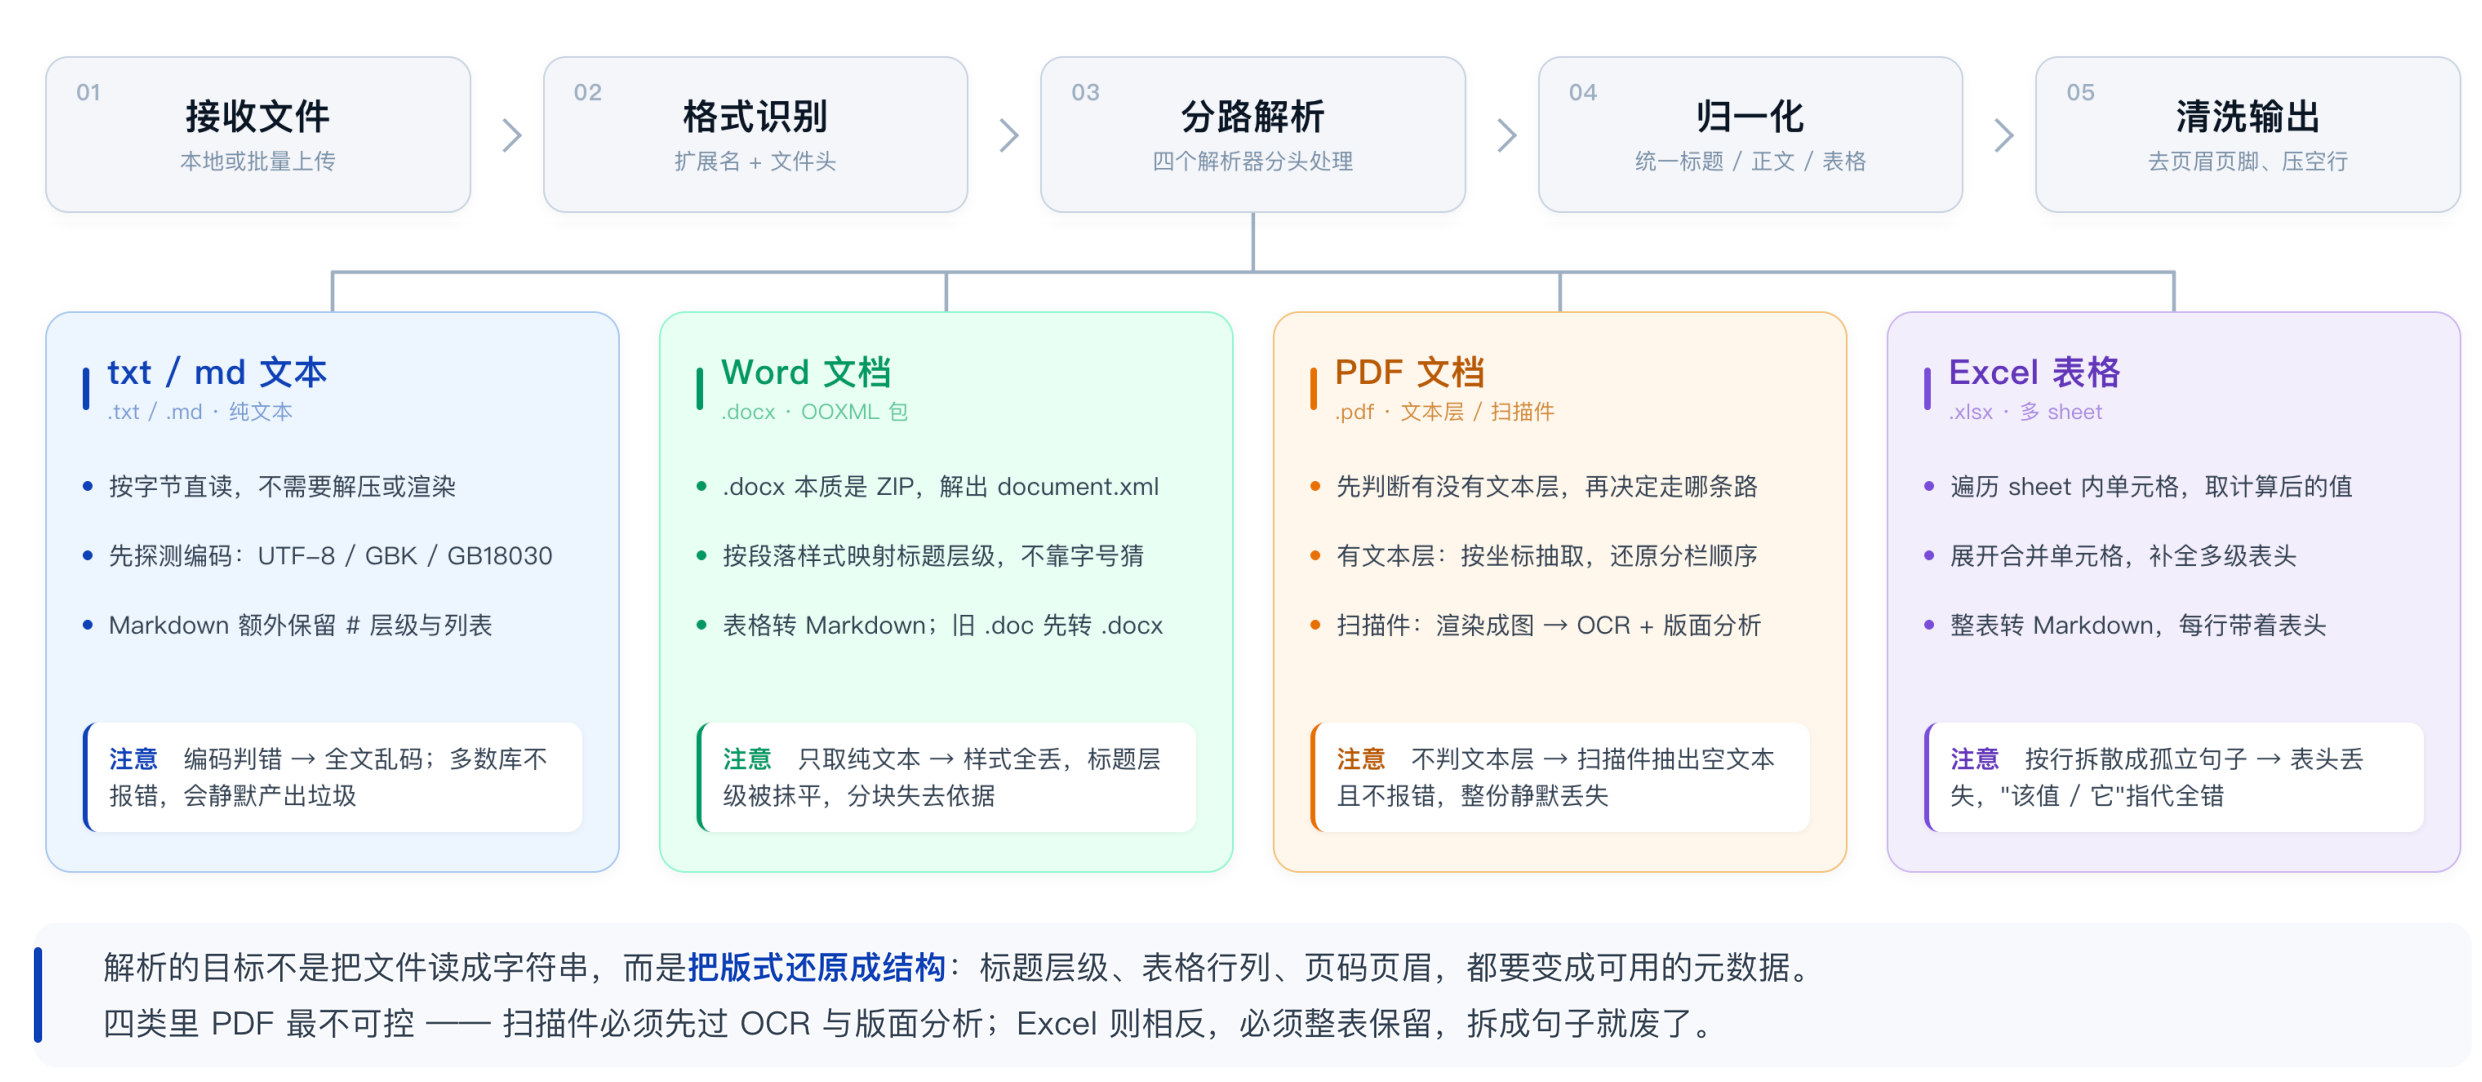

### 方法一：使用 Langchain 中的文档加载器 `document_loaders`

#### 加载 PDF

In [1]:
# pip install pymupdf
from langchain_community.document_loaders import PyMuPDFLoader
loader = PyMuPDFLoader("../data/Reflexion.pdf", extract_images=True)
docs = loader.load()
print(f"文档数量{len(docs)}")
for i, doc in enumerate(docs):
    print(f"================Doc_{i}.metadata=====================")
    print("metadata = ", doc.metadata)
    print(f"================Doc_{i}.page_content=====================")
    print("page_content = ", doc.page_content)

文档数量19
================Doc_0.metadata=====================
metadata =  {'producer': 'pdfTeX-1.40.25', 'creator': 'LaTeX with hyperref', 'creationdate': '2023-10-11T00:21:22+00:00', 'source': '../data/Reflexion.pdf', 'file_path': '../data/Reflexion.pdf', 'total_pages': 19, 'format': 'PDF 1.5', 'title': '', 'author': '', 'subject': '', 'keywords': '', 'moddate': '2023-10-11T00:21:22+00:00', 'trapped': '', 'modDate': 'D:20231011002122Z', 'creationDate': 'D:20231011002122Z', 'page': 0}
================Doc_0.page_content=====================
page_content =  Reflexion: Language Agents with
Verbal Reinforcement Learning
Noah Shinn
Northeastern University
noahshinn024@gmail.com
Federico Cassano
Northeastern University
cassano.f@northeastern.edu
Edward Berman
Northeastern University
berman.ed@northeastern.edu
Ashwin Gopinath
Massachusetts Institute of Technology
agopi@mit.edu
Karthik Narasimhan
Princeton University
karthikn@princeton.edu
Shunyu Yao
Princeton University
shunyuy@princeton.edu
Abs

#### 加载 txt

In [2]:
from langchain_community.document_loaders import TextLoader
loader = TextLoader("../data/deepseek百度百科.txt", encoding="utf-8")
docs = loader.load()
print(f"文档数量{len(docs)}")
for i, doc in enumerate(docs):
    print(f"================Doc_{i}.metadata=====================")
    print("metadata = ", doc.metadata)
    print(f"================Doc_{i}.page_content=====================")
    print("page_content = ", doc.page_content)

文档数量1
================Doc_0.metadata=====================
metadata =  {'source': '../data/deepseek百度百科.txt'}
================Doc_0.page_content=====================
page_content =  DeepSeek，全称杭州深度求索人工智能基础技术研究有限公司。DeepSeek是一家创新型科技公司，成立于2023年7月17日 ，使用数据蒸馏技术，得到更为精炼、有用的数据。由知名私募巨头幻方量化孕育而生，专注于开发先进的大语言模型（LLM）和相关技术。注册地址：浙江省杭州市拱墅区环城北路169号汇金国际大厦西1幢1201室。法定代表人为裴湉，经营范围包括技术服务、技术开发、软件开发等。
2024年1月5日至6月，相继发布DeepSeek LLM、DeepSeek-Coder、DeepSeekMath、DeepSeek-VL、DeepSeek-V2、DeepSeek-Coder-V2模型。 2024年9月5日，更新API支持文档，宣布合并DeepSeek Coder V2和DeepSeek V2 Chat，推出DeepSeek V2.5。12月13日，发布DeepSeek-VL2。12月26日，正式上线DeepSeek-V3首个版本并同步开源。2025年1月31日，英伟达宣布DeepSeek-R1模型登陆NVIDIANIM。同一时段内，亚马逊和微软也接入DeepSeek-R1模型。 2月5日，DeepSeek-R1、V3、Coder等系列模型，已陆续上线国家超算互联网平台。2月6日消息，澳大利亚政府以所谓“担心安全风险”为由，已禁止在所有政府设备中使用DeepSeek。2月8日，DeepSeek正式登陆苏州，并在苏州市公共算力服务平台上完成部署上线，为用户提供开箱即用的软硬件一体服务。 截至2月9日，DeepSeek App的累计下载量已超1.1亿次，周活跃用户规模最高近9700万。 2月20日消息，已有超200家企业宣布接入DeepSeek。 2月26日，DeepSeek宣布开源DeepGEMM。

发展历程
早期发展
DeepSeek成立于2023年7月17日，由知名量化资管巨头幻方量化创立。DeepSe

#### 加载 word

In [ ]:
from langchain_community.document_loaders import Docx2txtLoader
loader = Docx2txtLoader("../data/人事管理流程.docx")
docs = loader.load()
print(docs)

#### 加载网页

In [ ]:
import bs4
from langchain_community.document_loaders import WebBaseLoader
web_path = "https://www.news.cn/fortune/20251218/93d4a4212fd34985ad05d178a27c7c75/c.html"
loader = WebBaseLoader(
    web_path=[web_path],
    bs_kwargs=dict(parse_only = bs4.SoupStrainer(class_=("main-left left", "title")))
)
docs = loader.load()
print(docs)  # Document对象

### 方法二：使用现成的工具或服务

#### MinerU



官网：https://mineru.net/

安装 `uv add mineru-open-sdk langchain-mineru`

设置环境变量 `MINERU_TOKEN`

SDK

In [16]:
# 1. 初始化 MinerU 客户端
import os
from dotenv import load_dotenv
from mineru import MinerU
load_dotenv()
client = MinerU(token = os.getenv("MINERU_TOKEN"))

In [17]:
# 2. 快速解析
# No token needed for Flash Mode
result = client.flash_extract("../data/pdf_test.pdf")
print(result.markdown)

# Reflexion: Language Agents with Verbal Reinforcement Learning

Noah Shinn Northeastern University noahshinn024@gmail.com

Edward Berman Northeastern University berman.ed@northeastern.edu

Karthik Narasimhan Princeton University karthikn@princeton.edu

Federico Cassano Northeastern University cassano.f@northeastern.edu

Ashwin Gopinath Massachusets Institute of Technology agopi@mit.edu

Shunyu Yao Princeton University shunyuy@princeton.edu

## Abstract

Large language models (LLMs) have been increasingly used to interact with exter-nal environments (e.g., games, compilers, APIs) as goal-driven agents. However, it remains challenging for these language agents to quickly and efficiently learn from trial-and-error as traditional reinforcement learning methods require extensive training samples and expensive model fine-tuning. We propose Reflexion,a novel framework to reinforce language agents not by updating weights, but instead through linguistic feedback. Concretely,Reflexion agents ve

In [18]:
# 3. 精准解析
# Get your free token from https://mineru.net
result = client.extract("../data/pdf_test.pdf")
print(result.markdown)
print(result.images) # Access extracted images

# Reflexion: Language Agents with Verbal Reinforcement Learning

Noah Shinn
Northeastern University
noahshinn024@gmail.com

Edward Berman
Northeastern University
berman.ed@northeastern.edu

Karthik Narasimhan
Princeton University
karthikn@princeton.edu

Federico Cassano
Northeastern University
cassano.f@northeastern.edu

Ashwin Gopinath
Massachusetts Institute of Technology
agopi@mit.edu

Shunyu Yao
Princeton University
shunyuy@princeton.edu

## Abstract

Large language models (LLMs) have been increasingly used to interact with external environments (e.g., games, compilers, APIs) as goal-driven agents. However, it remains challenging for these language agents to quickly and efficiently learn from trial-and-error as traditional reinforcement learning methods require extensive training samples and expensive model fine-tuning. We propose Reflexion, a novel framework to reinforce language agents not by updating weights, but instead through linguistic feedback. Concretely, Reflexion agents 

In [21]:
# 4. 保存到本地
result.save_all("mineru_output")

WindowsPath('mineru_output')

In [ ]:
# 5. OCR支持(pdf是扫描件)
# result = client.extract("../data/pdf_test.pdf", ocr=True)
# print(result.markdown)

result = client.extract("../data/pdf_test.pdf")langchain

In [10]:
from langchain_mineru import MinerULoader
loader = MinerULoader(
    source="../data/pdf_test.pdf",
    mode="flash", # 可选, "flash", "precision"
    # token=os.getenv("MINERU_TOKEN"),
    # ocr=True
)
docs = loader.load()
print(docs[0].page_content[:500])
print(docs[0].metadata)

# Reflexion: Language Agents with Verbal Reinforcement Learning

Noah Shinn Northeastern University noahshinn024@gmail.com

Edward Berman Northeastern University berman.ed@northeastern.edu

Karthik Narasimhan Princeton University karthikn@princeton.edu

Federico Cassano Northeastern University cassano.f@northeastern.edu

Ashwin Gopinath Massachusets Institute of Technology agopi@mit.edu

Shunyu Yao Princeton University shunyuy@princeton.edu

## Abstract

Large language models (LLMs) have been in
{'source': '../data/pdf_test.pdf', 'loader': 'mineru', 'output_format': 'markdown', 'mode': 'flash', 'language': 'ch', 'pages': None, 'split_pages': False, 'filename': None}


#### 文档解析工具对比
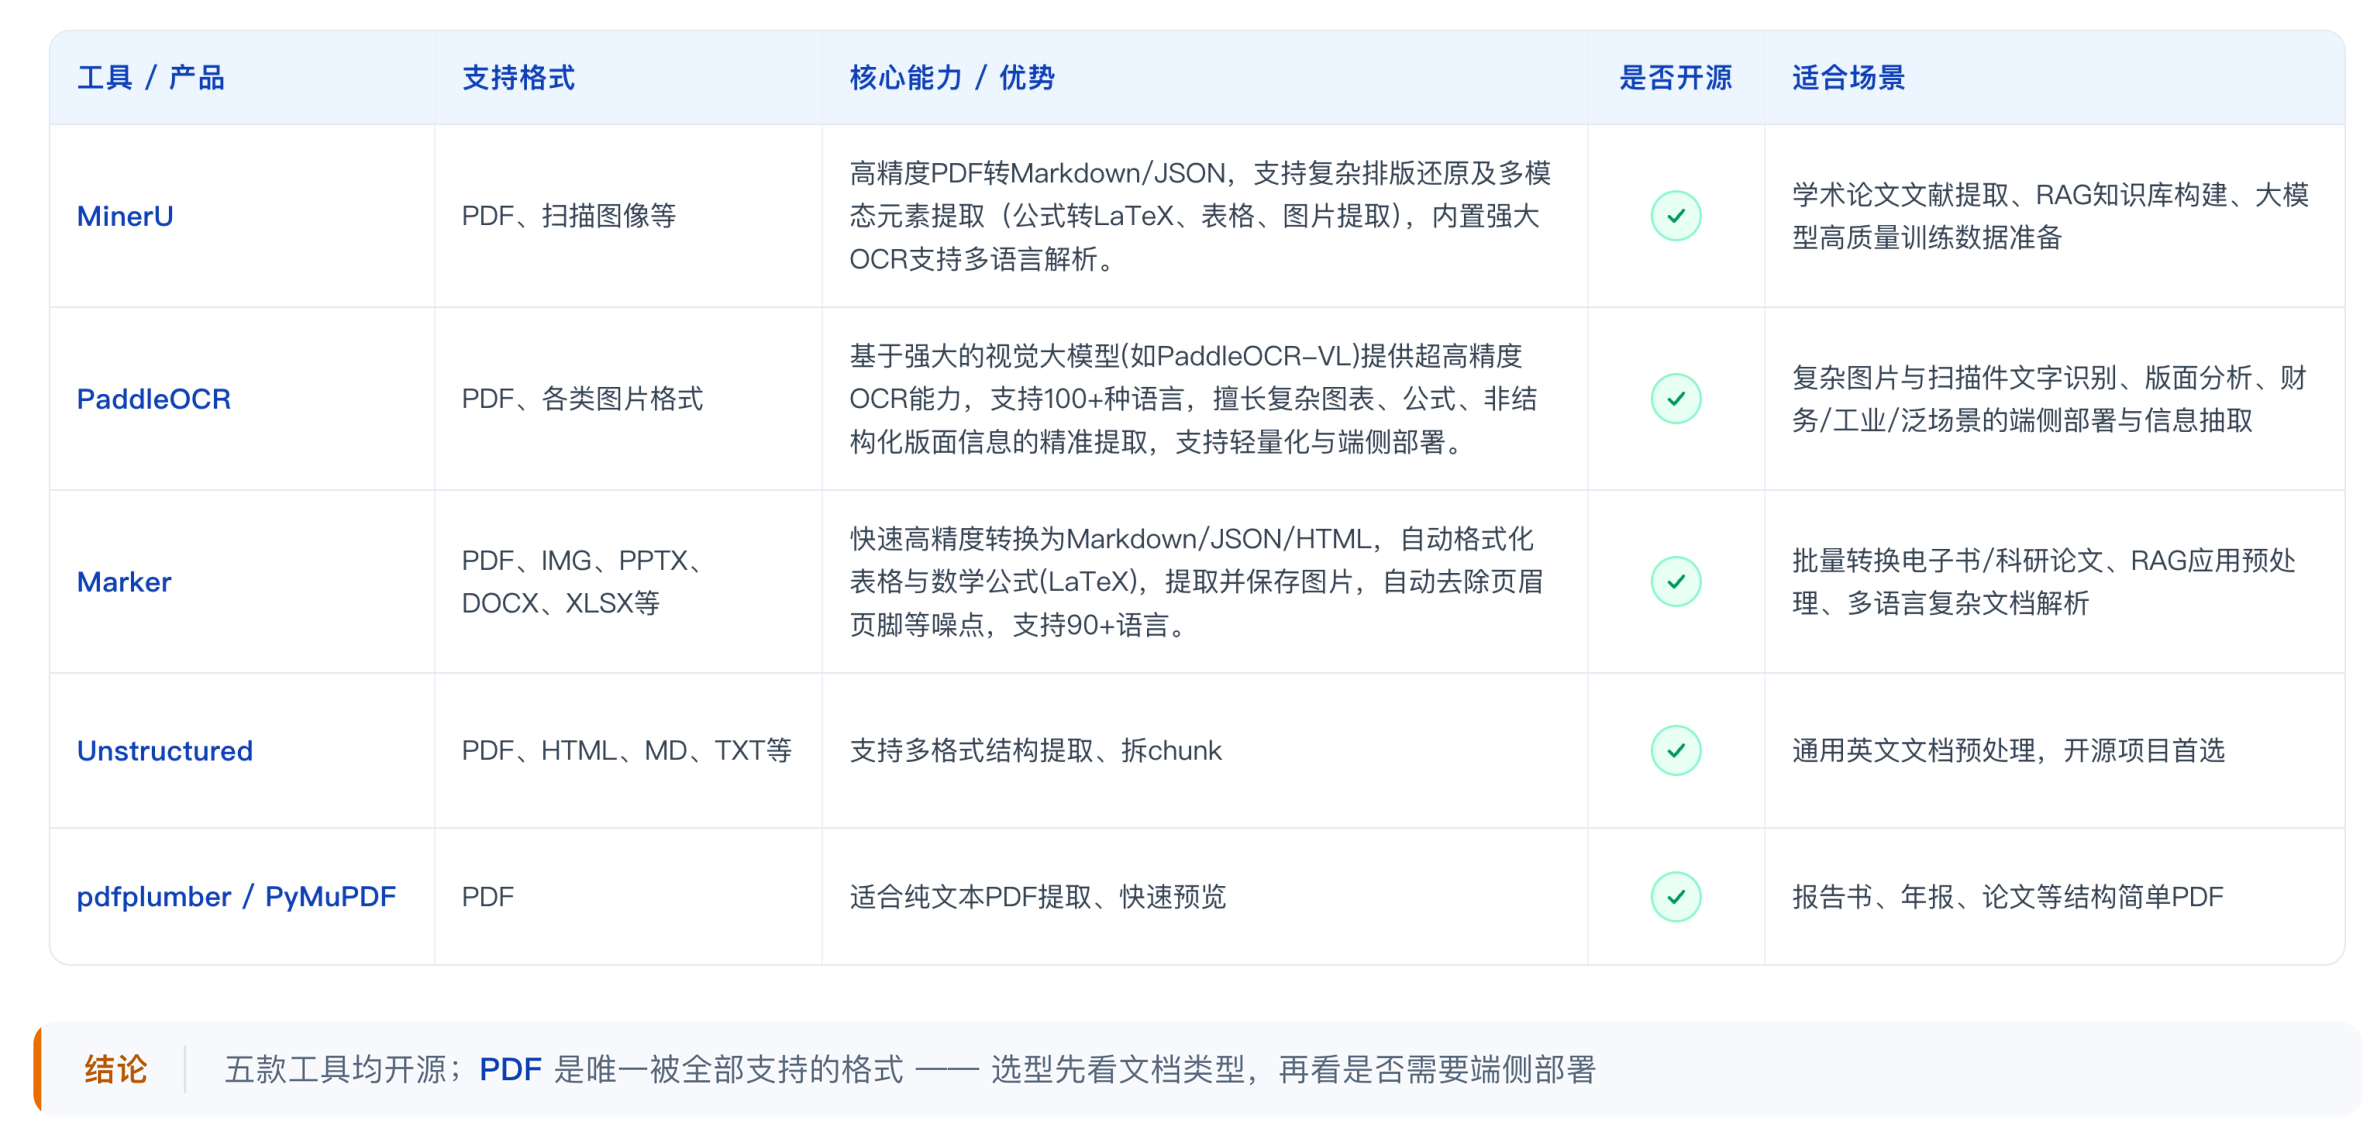

### 拓展

#### 1. BaseLoader

LangChain 的 `BaseLoader` 抽象基类，它定义了“文档加载器”的统一接口：把 PDF、网页、数据库、Word、日志等各种数据源，统一转换成 `Document` 对象

子类应该怎么实现？

通常只需继承 `BaseLoader`，并在构造函数里接收数据源信息，然后实现 `lazy_load()`

In [ ]:
from langchain_core.document_loaders import BaseLoader
from langchain_core.documents import Document

class MyFileLoader(BaseLoader):
    def __init__(self, file_path: str, encoding: str = "utf-8"):
        self.file_path = file_path
        self.encoding = encoding

    def lazy_load(self):
        with open(self.file_path, encoding=self.encoding) as f:
            for line_num, line in enumerate(f):
                yield Document(
                    page_content=line.rstrip(),
                    metadata={
                        "source": self.file_path,
                        "line_number": line_num,
                    },
                )

loader = MyFileLoader("../data/deepseek百度百科.txt")
docs = loader.load()
print(docs)

#### 2. Document

每个 `Document` 对象的结构大致如下：

In [ ]:
Document(
    page_content="这是一段文档内容...",
    metadata={
        "source": "document.pdf",
        "page": 3,
        "author": "张三"
    }
)

如何添加元数据

In [ ]:
# 1. 创建时直接传入
doc = Document(
    page_content="Python 的列表可以保存多个元素……",
    metadata={
        "source": "Python 基础教程.pdf",
        "page": 26,
        "chapter": "列表与元组",
        "author": "张三",
        "category": "Python",
        "updated_at": "2026-10-01",
    },
)

# 2. 创建后追加
doc.metadata["version"] = "v2.1"
doc.metadata["department"] = "研发部"

In [ ]:
# 3. 从 Loader 自动获得
# - PDF Loader 通常会带上文件路径、页码等信息
# - 网页 Loader 会带上 URL
from langchain_community.document_loaders import PyPDFLoader
loader = PyPDFLoader("../data/Reflexion.pdf")
docs = loader.load()
print(docs[1].metadata)
# 例如：{'source': 'book.pdf', 'page': 0, ...}

In [ ]:
# 4. 切分后增强
from langchain_text_splitters import RecursiveCharacterTextSplitter
splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
chunks = splitter.split_documents([doc])

for chunk in chunks:
    chunk.metadata["chunk_type"] = "introduction"

print(chunks[0].metadata)